In [5]:
import lancedb
import polars as pl
from scipy.spatial import distance
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt
import numpy as np
import random

In [79]:
uri = "../../data/pokemon_db"
db = lancedb.connect(uri)

db.list_tables()

ListTablesResponse(context=None, tables=['pokemon'], page_token=None)

In [80]:
table = db.open_table("pokemon")
df = table.search().to_polars()

df

dex_num,name,page_title,image_path,text,image_vector,text_vector
str,str,str,str,str,"array[f32, 1024]","array[f32, 1024]"
"""0001""","""Bulbasaur""","""Bulbasaur (Pokémon)""","""data/pokemon_data/images/0001_…","""Bulbasaur is a small, quadrupe…","[0.009552, 0.042646, … 0.012425]","[0.488401, 2.604806, … -0.158971]"
"""0002""","""Ivysaur""","""Ivysaur (Pokémon)""","""data/pokemon_data/images/0002_…","""Ivysaur is a quadrupedal amphi…","[0.009569, 0.043917, … 0.023321]","[3.156766, 2.03966, … 2.216954]"
"""0003""","""Venusaur""","""Venusaur (Pokémon)""","""data/pokemon_data/images/0003_…","""Venusaur is a squat, quadruped…","[0.019082, 0.030828, … 0.004789]","[3.346082, 3.002894, … -1.35448]"
"""0004""","""Charmander""","""Charmander (Pokémon)""","""data/pokemon_data/images/0004_…","""Charmander is a bipedal, repti…","[0.007554, 0.030683, … 0.00532]","[-2.461749, 2.43778, … 0.304722]"
"""0005""","""Charmeleon""","""Charmeleon (Pokémon)""","""data/pokemon_data/images/0005_…","""Charmeleon is a bipedal, repti…","[0.022615, 0.02371, … 0.013143]","[0.909607, 4.071574, … -0.847041]"
…,…,…,…,…,…,…
"""1020""","""Gouging Fire""","""Gouging Fire (Pokémon)""","""data/pokemon_data/images/1020_…","""Gouging Fire is a massive lion…","[0.031449, 0.003423, … 0.022354]","[-1.296814, 3.741295, … 2.221183]"
"""1021""","""Raging Bolt""","""Raging Bolt (Pokémon)""","""data/pokemon_data/images/1021_…","""Raging Bolt is a massive quadr…","[0.02579, -0.009269, … -0.001362]","[-1.16064, 0.550157, … 0.062238]"
"""1022""","""Iron Boulder""","""Iron Boulder (Pokémon)""","""data/pokemon_data/images/1022_…","""Iron Boulder is a spherical, b…","[0.024353, 0.02418, … 0.008821]","[2.738039, 6.29749, … -0.802212]"


In [81]:
sample_count = 50

use_image_flag = [True if i % 2 == 0 else False for i in range(sample_count)]
use_image_flag = random.sample(use_image_flag, len(use_image_flag))

df = df.sample(n=sample_count, shuffle=False).with_columns(
    use_image=pl.Series(use_image_flag)
).with_columns(
    query_vector=pl.when(pl.col("use_image")).then(pl.col("image_vector")).otherwise(pl.col("text_vector"))
)
df

dex_num,name,page_title,image_path,text,image_vector,text_vector,use_image,query_vector
str,str,str,str,str,"array[f32, 1024]","array[f32, 1024]",bool,"array[f32, 1024]"
"""0064""","""Kadabra""","""Kadabra (Pokémon)""","""data/pokemon_data/images/0064_…","""Kadabra is a primarily yellow,…","[0.033781, 0.002626, … -0.003693]","[1.919037, -1.128448, … 1.484044]",true,"[0.033781, 0.002626, … -0.003693]"
"""0074""","""Geodude""","""Geodude (Pokémon)""","""data/pokemon_data/images/0074_…","""Geodude is a khaki boulder -li…","[0.003443, 0.036389, … -0.00046]","[2.59079, 2.37489, … -1.422679]",false,"[2.59079, 2.37489, … -1.422679]"
"""0079""","""Slowpoke""","""Slowpoke (Pokémon)""","""data/pokemon_data/images/0079_…","""Slowpoke is a pink Pokémon tha…","[0.002296, 0.019221, … 0.006223]","[-3.183792, 2.70488, … -0.582228]",true,"[0.002296, 0.019221, … 0.006223]"
"""0085""","""Dodrio""","""Dodrio (Pokémon)""","""data/pokemon_data/images/0085_…","""Dodrio is a large, wingless, t…","[0.005157, -0.008098, … 0.023918]","[0.927571, -1.929755, … 3.805247]",true,"[0.005157, -0.008098, … 0.023918]"
"""0123""","""Scyther""","""Scyther (Pokémon)""","""data/pokemon_data/images/0123_…","""Scyther is a bipedal, insectoi…","[0.012372, 0.004028, … 0.039118]","[-1.139157, -1.394511, … 0.81463]",false,"[-1.139157, -1.394511, … 0.81463]"
…,…,…,…,…,…,…,…,…
"""0947""","""Brambleghast""","""Brambleghast (Pokémon)""","""data/pokemon_data/images/0947_…","""Brambleghast is a tumbleweed-l…","[0.024697, 0.020409, … -0.005242]","[2.98831, 1.763217, … -2.185212]",false,"[2.98831, 1.763217, … -2.185212]"
"""0967""","""Cyclizar""","""Cyclizar (Pokémon)""","""data/pokemon_data/images/0967_…","""Cyclizar is a green reptilian …","[0.010055, 0.006509, … 0.016832]","[3.617691, 0.478517, … 3.013072]",true,"[0.010055, 0.006509, … 0.016832]"
"""0968""","""Orthworm""","""Orthworm (Pokémon)""","""data/pokemon_data/images/0968_…","""Orthworm is a long, worm-like …","[-0.011691, 0.004298, … 0.001433]","[-1.344726, 1.373118, … 0.252513]",false,"[-1.344726, 1.373118, … 0.252513]"


In [82]:
image_dict = dict(df["name", "use_image"].iter_rows())

image_dict

{'Kadabra': True,
 'Geodude': False,
 'Slowpoke': True,
 'Dodrio': True,
 'Scyther': False,
 'Magmar': True,
 'Lapras': False,
 'Sentret': True,
 'Xatu': False,
 'Umbreon': True,
 'Pineco': False,
 'Granbull': False,
 'Magcargo': False,
 'Tyrogue': True,
 'Zangoose': False,
 'Whiscash': True,
 'Anorith': False,
 'Milotic': True,
 'Staraptor': True,
 'Vespiquen': False,
 'Cherubi': True,
 'Lumineon': True,
 'Palkia': False,
 'Giratina': False,
 'Watchog': False,
 'Pansage': False,
 'Woobat': True,
 'Sewaddle': True,
 'Lampent': False,
 'Beartic': False,
 'Bisharp': True,
 'Froakie': True,
 'Inkay': True,
 'Barbaracle': True,
 'Clawitzer': True,
 'Rowlet': True,
 'Komala': False,
 'Tapu Koko': False,
 'Morgrem': False,
 'Alcremie': False,
 'Falinks': False,
 'Zarude': True,
 'Oinkologne': True,
 'Armarouge': False,
 'Wattrel': True,
 'Brambleghast': False,
 'Cyclizar': True,
 'Orthworm': False,
 'Greavard': True,
 'Sandy Shocks': False}

In [83]:
distance_matrix = distance.cdist(df["query_vector"], df["query_vector"], metric="cosine")
np.fill_diagonal(distance_matrix, 0)

distance_matrix

array([[0.        , 0.74300229, 0.27365177, ..., 0.77511341, 0.39836659,
        0.71309651],
       [0.74300229, 0.        , 0.8018037 , ..., 0.63799679, 0.79035164,
        0.42783049],
       [0.27365177, 0.8018037 , 0.        , ..., 0.78474904, 0.36251533,
        0.77848682],
       ...,
       [0.77511341, 0.63799679, 0.78474904, ..., 0.        , 0.80987767,
        0.62543155],
       [0.39836659, 0.79035164, 0.36251533, ..., 0.80987767, 0.        ,
        0.79363135],
       [0.71309651, 0.42783049, 0.77848682, ..., 0.62543155, 0.79363135,
        0.        ]], shape=(50, 50))

In [84]:
cond_distance_matrix = distance.squareform(distance_matrix)
cond_distance_matrix

array([0.74300229, 0.27365177, 0.3039835 , ..., 0.80987767, 0.62543155,
       0.79363135], shape=(1225,))

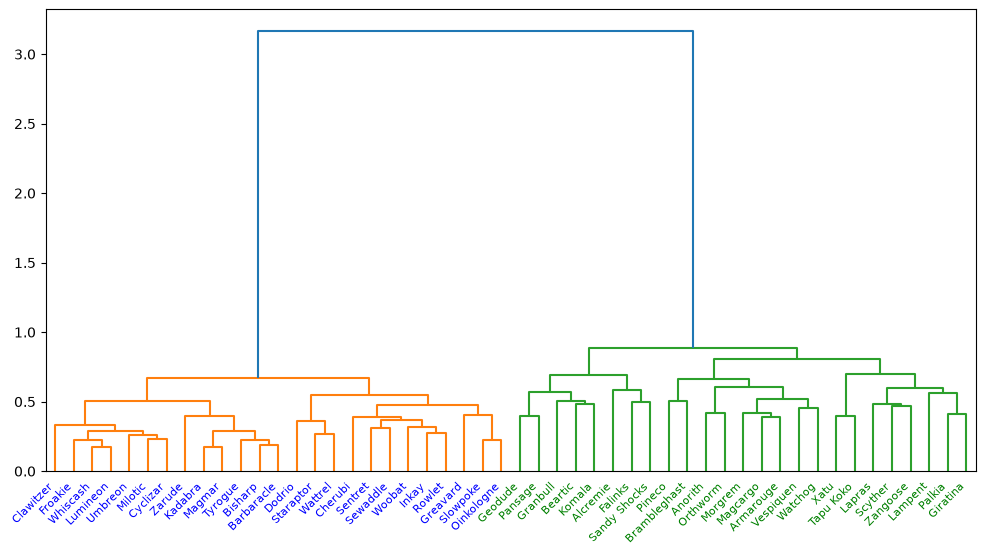

In [85]:
linkage_data = linkage(cond_distance_matrix, method='ward')

plt.figure(figsize=(12, 6))
ax = plt.subplot(111)
dendrogram(linkage_data, labels=df["name"])

for xtick in ax.get_xticklabels():
    label = xtick.get_text()
    if label not in image_dict:
        raise ValueError(f"Label {label} missing from dict")
    if image_dict[xtick.get_text()]:
        xtick.set_color('b')
    else:
        xtick.set_color('g')

plt.xticks(rotation=45, ha="right")


plt.savefig("test_cluster.png")
plt.show()